Paquetes necesarios

In [44]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



Detectamos las monedas umbralizando los contornos, detectando los distintos tamaños de las mismas. Cuando el usuario hace clic en la moneda de 1€, el programa usa esta misma moneda de referencia para clasificar las otras por tamaño. Finalmente indica el valor de cada moneda y muestra el total en la parte superior izquierda.

In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Diámetros reales de las monedas en mm: {valor en euros: diámetro}
MONEDAS_MM = {
    0.01: 16.25,
    0.02: 18.75,
    0.05: 21.25,
    0.10: 19.75,
    0.20: 22.25,
    0.50: 24.35,   # valor del enunciado
    1.00: 23.25,
    2.00: 25.75,
}

DIAMETRO_1EURO = MONEDAS_MM[1.00]
TOLERANCIA_MM = 1.5   # si ninguna moneda se parece a menos de esto, se marca como "?"


def detectar_monedas(img_bgr, area_min=500, circularidad_min=0.8):
    """Devuelve una lista de monedas (x, y, radio_en_pixeles) y la imagen binaria usada."""
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (7, 7), 0)

    # Otsu invertido: monedas en blanco, fondo en negro
    _, binaria = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # El fondo suele ser la parte más grande: si hay más blanco que negro, invertimos
    if np.mean(binaria) > 127:
        binaria = 255 - binaria

    # Limpieza: cerrar huecos dentro de las monedas y quitar ruido pequeño
    kernel = np.ones((5, 5), np.uint8)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, kernel)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, kernel)

    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    monedas = []
    for c in contornos:
        area = cv2.contourArea(c)
        if area < area_min:
            continue
        perimetro = cv2.arcLength(c, True)
        # Circularidad: 1 para un círculo perfecto, menor para otras formas
        circularidad = 4 * np.pi * area / (perimetro ** 2)
        if circularidad < circularidad_min:
            continue
        (x, y), _ = cv2.minEnclosingCircle(c)
        radio = np.sqrt(area / np.pi)   # radio a partir del área
        monedas.append((x, y, radio))
    return monedas, binaria


def moneda_en_punto(monedas, punto):
    """Índice de la moneda que contiene al punto (x, y), o None si no hay ninguna."""
    mejor, mejor_dist = None, None
    for i, (x, y, r) in enumerate(monedas):
        dist = np.hypot(x - punto[0], y - punto[1])
        if dist <= r and (mejor_dist is None or dist < mejor_dist):
            mejor, mejor_dist = i, dist
    return mejor


def calibrar(radio_px, diametro_mm=DIAMETRO_1EURO):
    """Milímetros que mide un píxel, sabiendo el diámetro real de una moneda."""
    return diametro_mm / (2 * radio_px)


def clasificar_moneda(radio_px, mm_por_px):
    """Devuelve (valor, diametro_mm). Si no encaja con ninguna moneda, valor es None."""
    diametro = 2 * radio_px * mm_por_px
    valor = min(MONEDAS_MM, key=lambda v: abs(MONEDAS_MM[v] - diametro))
    if abs(MONEDAS_MM[valor] - diametro) > TOLERANCIA_MM:
        return None, diametro
    return valor, diametro


def procesar_monedas(img_bgr, monedas, mm_por_px):
    """Dibuja las monedas sobre la imagen. Devuelve (imagen, total en euros, conteo por valor)."""
    salida = img_bgr.copy()
    total = 0.0
    conteo = Counter()
    for (x, y, r) in monedas:
        centro = (int(x), int(y))
        escala_texto = max(0.5, r / 50)
        if mm_por_px is None:
            # Sin calibrar: solo marcamos las monedas en amarillo
            cv2.circle(salida, centro, int(r), (0, 255, 255), 2)
            continue
        valor, diametro = clasificar_moneda(r, mm_por_px)
        if valor is None:
            cv2.circle(salida, centro, int(r), (0, 0, 255), 2)
            texto = "?"
        else:
            total += valor
            conteo[valor] += 1
            cv2.circle(salida, centro, int(r), (0, 255, 0), 2)
            texto = f"{valor:.2f}"
        cv2.putText(salida, texto, (centro[0] - int(r / 2), centro[1]),
                    cv2.FONT_HERSHEY_SIMPLEX, escala_texto, (255, 0, 0), 2)
    return salida, round(total, 2), conteo


def pedir_clic(img_bgr, titulo="Haz clic en una moneda de 1 euro (ESC para cancelar)"):
    """Muestra la imagen y devuelve el punto (x, y) donde el usuario hace clic."""
    puntos = []

    def raton(evento, x, y, flags, param):
        if evento == cv2.EVENT_LBUTTONDOWN:
            puntos.append((x, y))

    cv2.namedWindow(titulo, cv2.WINDOW_NORMAL)
    cv2.setMouseCallback(titulo, raton)
    while len(puntos) == 0:
        cv2.imshow(titulo, img_bgr)
        if cv2.waitKey(20) & 0xFF == 27:   # ESC
            break
    cv2.destroyAllWindows()
    cv2.waitKey(1)
    return puntos[0] if puntos else None


Monedas detectadas: 8
Radio de la moneda de referencia: 93.1 px
Escala: 0.1249 mm/píxel
  1 x 0.01 €
  1 x 0.02 €
  1 x 0.05 €
  1 x 0.10 €
  1 x 0.20 €
  1 x 0.50 €
  1 x 1.00 €
  1 x 2.00 €
TOTAL: 3.88 €


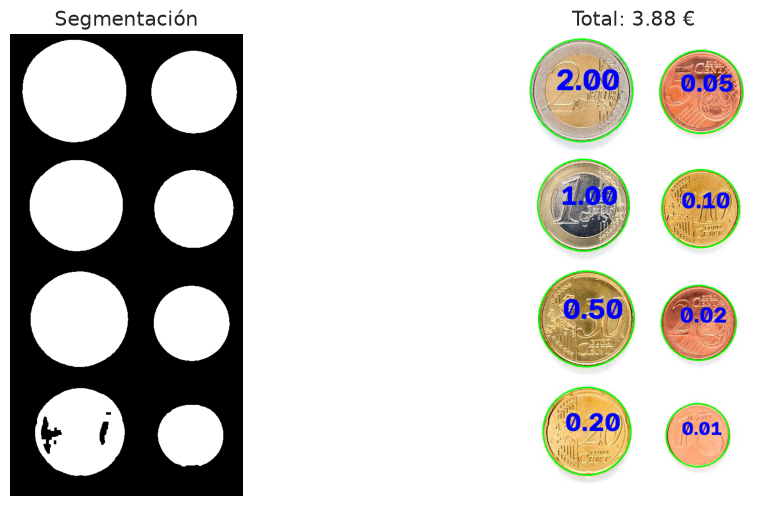

In [46]:
# --- Imagen ideal ---
img_monedas = cv2.imread('Monedas.jpg')
if img_monedas is None:
    raise FileNotFoundError("No se encuentra Monedas.jpg (debe estar junto al notebook)")

monedas, binaria = detectar_monedas(img_monedas)
print('Monedas detectadas:', len(monedas))

# 1) Clic en una moneda de 1 euro para calibrar
punto = pedir_clic(img_monedas)
# Si no puedes usar la ventana de OpenCV, descomenta y pon las coordenadas (x, y) de un 1 euro:
# punto = (350, 420)

idx = moneda_en_punto(monedas, punto) if punto else None
if idx is None:
    raise ValueError("El clic no cayó sobre ninguna moneda detectada")

# 2) Escala píxeles -> mm
radio_ref = monedas[idx][2]
mm_por_px = calibrar(radio_ref)
print(f'Radio de la moneda de referencia: {radio_ref:.1f} px')
print(f'Escala: {mm_por_px:.4f} mm/píxel')

# 3) Clasificar todas las monedas y sumar
img_resultado, total, conteo = procesar_monedas(img_monedas, monedas, mm_por_px)

for valor in sorted(conteo):
    print(f'  {conteo[valor]} x {valor:.2f} €')
print(f'TOTAL: {total:.2f} €')

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.axis("off")
plt.imshow(binaria, cmap='gray')
plt.title('Segmentación')
plt.subplot(1, 2, 2)
plt.axis("off")
plt.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
plt.title(f'Total: {total:.2f} €')
plt.show()


Demostrador en vivo (cámara)

Usa las mismas funciones de arriba. Controles de la ventana:
- **Clic** sobre una moneda de 1 € → calibra (la escala se guarda hasta que la cambies).
- **r** → borrar la calibración.
- **q** o **ESC** → salir.

Antes de calibrar las monedas se marcan en amarillo. Tras calibrar: verde = moneda reconocida, rojo con "?" = objeto que no encaja con ninguna moneda.

In [47]:
def demo_camara(indice_camara=0):
    cap = cv2.VideoCapture(indice_camara)
    if not cap.isOpened():
        print("No se pudo abrir la cámara")
        return

    estado = {'clic': None, 'mm_por_px': None}

    def raton(evento, x, y, flags, param):
        if evento == cv2.EVENT_LBUTTONDOWN:
            estado['clic'] = (x, y)

    ventana = 'Monedas en vivo'
    cv2.namedWindow(ventana)
    cv2.setMouseCallback(ventana, raton)

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        # El área mínima depende de la resolución de la cámara
        alto, ancho = frame.shape[:2]
        monedas, _ = detectar_monedas(frame, area_min=int(0.002 * alto * ancho))

        # Si hubo clic, intentamos calibrar con la moneda pulsada
        if estado['clic'] is not None:
            idx = moneda_en_punto(monedas, estado['clic'])
            if idx is not None:
                estado['mm_por_px'] = calibrar(monedas[idx][2])
            estado['clic'] = None

        salida, total, conteo = procesar_monedas(frame, monedas, estado['mm_por_px'])

        if estado['mm_por_px'] is None:
            texto = "Haz clic en una moneda de 1 euro para calibrar"
        else:
            texto = f"Total: {total:.2f} EUR"
        cv2.putText(salida, texto, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4)
        cv2.putText(salida, texto, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        cv2.imshow(ventana, salida)

        tecla = cv2.waitKey(1) & 0xFF
        if tecla in (ord('q'), 27):
            break
        if tecla == ord('r'):
            estado['mm_por_px'] = None

    cap.release()
    cv2.destroyAllWindows()
    cv2.waitKey(1)


# Descomenta para lanzar el demostrador
demo_camara(0)


TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

## Solución Tarea 2: Clasificación de microplásticos (FRA / PEL / TAR)

**Pasos:**
1. **Segmentar** las partículas (suavizado → umbral sobre la diferencia con el color de fondo → morfología → contornos).
2. **Extraer características** de cada contorno (las del trabajo SMACC + intensidad y saturación medias).
3. **Entrenar** con las tres imágenes `FRA.png`, `PEL.png`, `TAR.png` (cada partícula segmentada es una muestra). Se usa un clasificador sencillo, **K vecinos más cercanos** sobre las características normalizadas (no es aprendizaje profundo).
4. **Evaluar** sobre `MPs_test.jpg` con las anotaciones `MPs_test_bbs.csv`: accuracy, precisión, recall, F1 y matriz de confusión. La imagen de test **no** se usa para entrenar.

In [48]:
import csv
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

CLASES = ['FRA', 'PEL', 'TAR']
AREA_MIN_MP = 150          # área mínima (px) para considerar algo una partícula. AJUSTAR según la resolución
METODO_SEG = 'fondo'       # 'fondo', 'otsu' o 'adaptativo' (este último si la iluminación no es uniforme)

# Todas las características que calculamos
NOMBRES_CARACT = ['area', 'perimetro', 'compacidad', 'area_contenedor',
                  'ratio_contenedor', 'ratio_elipse', 'ratio_distancias',
                  'gris_medio', 'saturacion_media']

# Características que usa el clasificador. Por defecto, las que no dependen del tamaño en píxeles
# (así no importa que las imágenes tengan distinta resolución). Se puede añadir 'area' y 'perimetro'.
CARACT_USADAS = ['compacidad', 'area_contenedor', 'ratio_contenedor', 'ratio_elipse',
                 'ratio_distancias', 'gris_medio', 'saturacion_media']
IDX_USADAS = [NOMBRES_CARACT.index(n) for n in CARACT_USADAS]


def segmentar_particulas(img_bgr, area_min=AREA_MIN_MP, metodo=METODO_SEG):
    """Devuelve la lista de contornos externos de las partículas y la imagen binaria."""
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)

    if metodo == 'adaptativo':
        binaria = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY_INV, 51, 10)
    elif metodo == 'otsu':
        _, binaria = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        # El fondo debe ser lo más abundante: si hay más blanco que negro, invertimos
        if np.mean(binaria) > 127:
            binaria = 255 - binaria
    else:
        # 'fondo': el color de fondo es la mediana de la imagen (las partículas son minoría).
        # Medimos cuánto se aleja cada píxel de ese color, así da igual que la partícula
        # sea más clara u oscura que el fondo.
        suave = cv2.GaussianBlur(img_bgr, (5, 5), 0)
        color_fondo = np.median(suave.reshape(-1, 3), axis=0)
        diferencia = np.sqrt(((suave.astype(np.float32) - color_fondo) ** 2).sum(axis=2))
        diferencia = np.clip(diferencia, 0, 255).astype(np.uint8)
        _, binaria = cv2.threshold(diferencia, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Quitar ruido pequeño y cerrar huecos
    kernel = np.ones((3, 3), np.uint8)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, kernel)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, kernel)

    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contornos = [c for c in contornos if cv2.contourArea(c) >= area_min]
    return contornos, binaria


def extraer_caracteristicas(c, gris, hsv):
    """Calcula las características de un contorno (mismo orden que NOMBRES_CARACT)."""
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)

    # Compacidad: perímetro^2 / área
    compacidad = perimetro ** 2 / area

    # Contenedor alineado con los ejes
    x, y, w, h = cv2.boundingRect(c)
    area_contenedor = area / (w * h)            # relación área partícula / área contenedor
    ratio_contenedor = min(w, h) / max(w, h)    # ancho/alto (siempre <= 1)

    # Relación entre los ejes de la elipse ajustada (necesita >= 5 puntos)
    if len(c) >= 5:
        (_, (eje1, eje2), _) = cv2.fitEllipse(c)
        if min(eje1, eje2) > 0:
            ratio_elipse = max(eje1, eje2) / min(eje1, eje2)
        else:
            ratio_elipse = 1.0
    else:
        ratio_elipse = 1.0

    # Centroide y relación entre distancia mínima y máxima al contorno
    M = cv2.moments(c)
    if M['m00'] > 0:
        cx, cy = M['m10'] / M['m00'], M['m01'] / M['m00']
    else:
        cx, cy = x + w / 2, y + h / 2
    puntos = c[:, 0, :].astype(float)
    dist = np.sqrt((puntos[:, 0] - cx) ** 2 + (puntos[:, 1] - cy) ** 2)
    ratio_distancias = dist.min() / dist.max()

    # Apariencia: gris y saturación medios dentro de la partícula (trabajamos en el recorte)
    mascara = np.zeros((h, w), np.uint8)
    cv2.drawContours(mascara, [c - np.array([x, y])], -1, 255, -1)
    gris_medio = cv2.mean(gris[y:y + h, x:x + w], mask=mascara)[0]
    saturacion_media = cv2.mean(hsv[y:y + h, x:x + w, 1], mask=mascara)[0]

    return [area, perimetro, compacidad, area_contenedor, ratio_contenedor,
            ratio_elipse, ratio_distancias, gris_medio, saturacion_media]


def caracteristicas_imagen(img_bgr):
    """Segmenta una imagen y devuelve (contornos, matriz de características, binaria)."""
    contornos, binaria = segmentar_particulas(img_bgr)
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    X = np.array([extraer_caracteristicas(c, gris, hsv) for c in contornos])
    return contornos, X, binaria


def leer_anotaciones(ruta_csv):
    """Lee el CSV y devuelve una lista de (etiqueta, x_min, y_min, x_max, y_max)."""
    anotaciones = []
    with open(ruta_csv, newline="") as f:
        for fila in csv.DictReader(f):
            x1, y1, x2, y2 = map(int, [fila["x_min"], fila["y_min"], fila["x_max"], fila["y_max"]])
            anotaciones.append((fila["label"], x1, y1, x2, y2))
    return anotaciones


def centroide(c):
    M = cv2.moments(c)
    if M['m00'] == 0:
        x, y, w, h = cv2.boundingRect(c)
        return x + w / 2, y + h / 2
    return M['m10'] / M['m00'], M['m01'] / M['m00']


def emparejar(contornos, anotaciones):
    """Para cada anotación busca el contorno más grande cuyo centroide cae dentro de su caja.
    Devuelve una lista con el índice del contorno (o None si no se detectó)."""
    centros = [centroide(c) for c in contornos]
    areas = [cv2.contourArea(c) for c in contornos]
    pares = []
    for (_, x1, y1, x2, y2) in anotaciones:
        candidatos = [i for i, (cx, cy) in enumerate(centros)
                      if x1 <= cx <= x2 and y1 <= cy <= y2]
        pares.append(max(candidatos, key=lambda i: areas[i]) if candidatos else None)
    return pares


### Entrenamiento con FRA.png, PEL.png y TAR.png

FRA: 161 partículas segmentadas
PEL: 118 partículas segmentadas
TAR: 55 partículas segmentadas


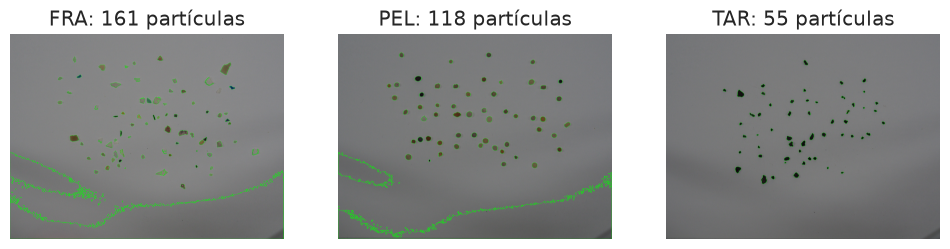


                         FRA       PEL       TAR
              area  20108.38  22176.52   2467.56
         perimetro    421.51    531.79    188.34
        compacidad     49.16     48.95     16.20
   area_contenedor      0.47      0.54      0.68
  ratio_contenedor      0.75      0.84      0.84
      ratio_elipse      1.85      1.49      1.45
  ratio_distancias      0.27      0.44      0.57
        gris_medio    109.80     91.78     27.04
  saturacion_media     25.46     38.22     24.83


In [ ]:
# Cargamos las tres imágenes de entrenamiento y extraemos características de cada partícula
imagenes_train = {'FRA': 'FRA.png', 'PEL': 'PEL.png', 'TAR': 'TAR.png'}

X_train, y_train = [], []
plt.figure(figsize=(12, 4))
for i, clase in enumerate(CLASES):
    img_c = cv2.imread(imagenes_train[clase])
    if img_c is None:
        raise FileNotFoundError(f"No se encuentra {imagenes_train[clase]}")
    contornos_c, X_c, binaria_c = caracteristicas_imagen(img_c)
    print(f'{clase}: {len(contornos_c)} partículas segmentadas')
    X_train.extend(X_c)
    y_train.extend([clase] * len(X_c))

    # Comprobación visual de la segmentación
    vis = img_c.copy()
    cv2.drawContours(vis, contornos_c, -1, (0, 255, 0), 2)
    plt.subplot(1, 3, i + 1)
    plt.axis("off")
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.title(f'{clase}: {len(contornos_c)} partículas')
plt.show()

X_train = np.array(X_train)
y_train = np.array(y_train)

# Resumen: media de cada característica por clase (para ver qué distingue a unas de otras)
print()
print(f'{"":>18}' + ''.join(f'{c:>10}' for c in CLASES))
for nombre in NOMBRES_CARACT:
    j = NOMBRES_CARACT.index(nombre)
    medias = [X_train[y_train == c, j].mean() for c in CLASES]
    print(f'{nombre:>18}' + ''.join(f'{m:>10.2f}' for m in medias))


In [50]:
# Normalizamos (media 0, desviación 1) para que ninguna característica pese más por su escala
escalador = StandardScaler()
X_train_n = escalador.fit_transform(X_train[:, IDX_USADAS])

# K vecinos más cercanos (k=3, o menos si hay pocas muestras)
k = min(3, len(X_train_n))
clasificador = KNeighborsClassifier(n_neighbors=k)
clasificador.fit(X_train_n, y_train)

# Precisión sobre el propio entrenamiento (solo orientativa, NO es la métrica final)
print('Accuracy en entrenamiento:', clasificador.score(X_train_n, y_train))


Accuracy en entrenamiento: 0.9401197604790419


### Evaluación sobre MPs_test.jpg

Partículas segmentadas: 41 | Partículas anotadas: 120
Anotaciones emparejadas: 39 | Sin partícula segmentada: 81
Accuracy  = 0.436
Precision = 0.190  (media ponderada)
Recall    = 0.436  (media ponderada)
F1 Score  = 0.265  (media ponderada)

              precision    recall  f1-score   support

         FRA       0.44      1.00      0.61        17
         PEL       0.00      0.00      0.00        11
         TAR       0.00      0.00      0.00        11

    accuracy                           0.44        39
   macro avg       0.15      0.33      0.20        39
weighted avg       0.19      0.44      0.26        39



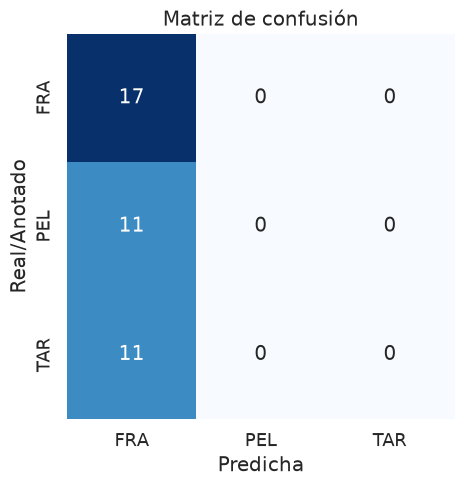

In [51]:
img_test = cv2.imread('MPs_test.jpg')
if img_test is None:
    raise FileNotFoundError("No se encuentra MPs_test.jpg")

contornos_t, X_t, binaria_t = caracteristicas_imagen(img_test)
anotaciones = leer_anotaciones('MPs_test_bbs.csv')
print(f'Partículas segmentadas: {len(contornos_t)} | Partículas anotadas: {len(anotaciones)}')

# Predicción de todas las partículas segmentadas
pred_todas = clasificador.predict(escalador.transform(X_t[:, IDX_USADAS]))

# Emparejamos cada anotación con su partícula segmentada
pares = emparejar(contornos_t, anotaciones)

y_real, y_pred = [], []
no_detectadas = 0
for (etiqueta, *_), idx in zip(anotaciones, pares):
    if idx is None:
        no_detectadas += 1
        continue
    y_real.append(etiqueta)
    y_pred.append(pred_todas[idx])

print(f'Anotaciones emparejadas: {len(y_real)} | Sin partícula segmentada: {no_detectadas}')

# Métricas
accuracy = accuracy_score(y_real, y_pred)
precision = precision_score(y_real, y_pred, labels=CLASES, average='weighted', zero_division=0)
recall = recall_score(y_real, y_pred, labels=CLASES, average='weighted', zero_division=0)
f1 = f1_score(y_real, y_pred, labels=CLASES, average='weighted', zero_division=0)

print(f"Accuracy  = {accuracy:.3f}")
print(f"Precision = {precision:.3f}  (media ponderada)")
print(f"Recall    = {recall:.3f}  (media ponderada)")
print(f"F1 Score  = {f1:.3f}  (media ponderada)")
print()
print(classification_report(y_real, y_pred, labels=CLASES, zero_division=0))

# Matriz de confusión
matriz = confusion_matrix(y_real, y_pred, labels=CLASES)
plt.figure(figsize=(5, 5))
sns.set(font_scale=1.2)
ax = sns.heatmap(matriz, annot=True, fmt='d', cbar=False, cmap='Blues',
                 xticklabels=CLASES, yticklabels=CLASES)
ax.set_xlabel("Predicha")
ax.set_ylabel("Real/Anotado")
ax.set_title("Matriz de confusión")
plt.show()


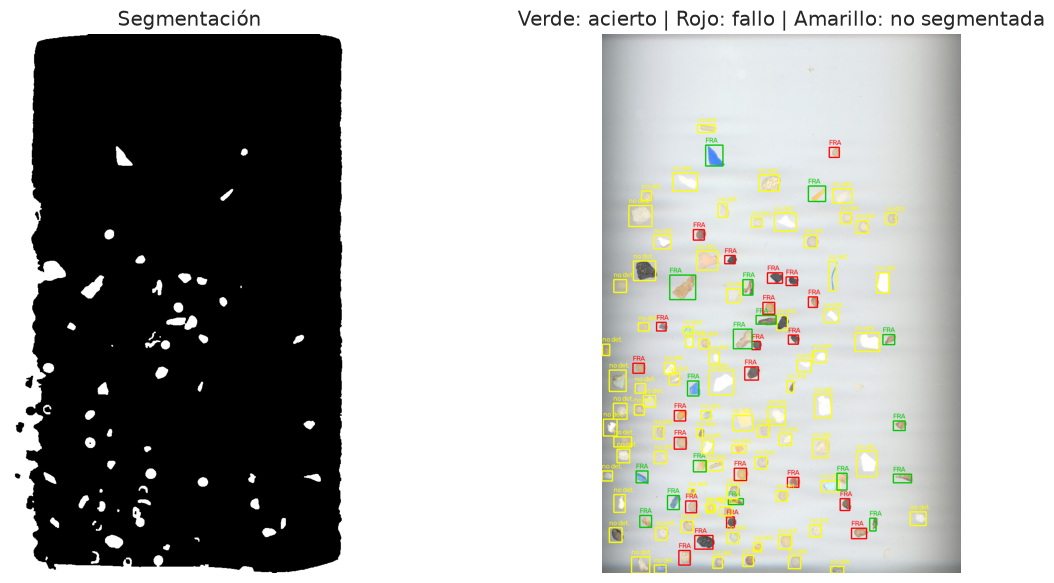

In [52]:
# Visualización: caja anotada coloreada según acierto (verde) o fallo (rojo), con la clase predicha
vis = img_test.copy()
for (etiqueta, x1, y1, x2, y2), idx in zip(anotaciones, pares):
    if idx is None:
        color, texto = (0, 255, 255), 'no det.'    # amarillo: no se segmentó
    else:
        pred = pred_todas[idx]
        color = (0, 200, 0) if pred == etiqueta else (0, 0, 255)
        texto = pred
    cv2.rectangle(vis, (x1, y1), (x2, y2), color, 2)
    cv2.putText(vis, texto, (x1, max(y1 - 5, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
plt.axis("off")
plt.imshow(binaria_t, cmap='gray')
plt.title('Segmentación')
plt.subplot(1, 2, 2)
plt.axis("off")
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('Verde: acierto | Rojo: fallo | Amarillo: no segmentada')
plt.show()


### Discusión

*(Completar con los resultados reales tras ejecutar.)* Aspectos a comentar:
- Qué clases se confunden más en la matriz de confusión y por qué (p. ej. fragmentos pequeños vs. pellets, o partículas oscuras vs. alquitrán).
- Cuántas anotaciones no llegaron a segmentarse (partículas pegadas que se funden en un solo contorno, bajo contraste, iluminación no uniforme).
- Qué características distinguen mejor las clases según la tabla de medias del entrenamiento.
- Posibles mejoras: umbral adaptativo o *watershed* para separar partículas pegadas, más muestras de entrenamiento, añadir más características de color.